Лабораторная работа №1. Регрессия

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score, KFold
from sklearn.pipeline import Pipeline,FeatureUnion
from sklearn.preprocessing import StandardScaler,SplineTransformer,FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer


Анализируем данные

In [4]:
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")
red["red"]=1
white["red"]=0
data=pd.concat([red,white],ignore_index=True)
print(f"{data.shape[0]} строк")
print(f"Красных {red.shape[0]}; Белых {white.shape[0]}")
print(f"Кол-во пропусков {data.isna().sum().sum()}")
print(f"Кол-во повторяющихся строк {data.duplicated().sum()}")
data=data.drop_duplicates().reset_index(drop=True)
print("После удаления дублированных строк:",end=' ')
print(f'Красных {(data["red"]==1).sum()}; Белых {(data["red"]==0).sum()}')
data.head()

6497 строк
Красных 1599; Белых 4898
Кол-во пропусков 0
Кол-во повторяющихся строк 1177
После удаления дублированных строк: Красных 1359; Белых 3961


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


In [13]:
description=data.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
description["skew"]=data.skew()
description.head(20)

,mean,std,min,25%,50%,75%,max,skew
fixed acidity,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000,1.650417
volatile acidity,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000,1.504557
citric acid,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000,0.484309
residual sugar,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000,1.706550
chlorides,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100,5.338237
free sulfur dioxide,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000,1.362719
total sulfur dioxide,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000,0.063614
density,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898,0.666326
pH,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000,0.389969
sulphates,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000,1.809454


(транспонировал таблицу,ведь describe ищут признаки по строкам)

Масштабы признаков сильно отличаются друг от друга, например total sulfur dioxide - 114.109023 и chlorides - 0.056690.
Для линейной модели потребуется масштабирование, иначе коэффициенты нельзя будет сравнивать.

Присутствуют признаки с сильной скошенностью
Например,chlorides: на квантили 75 значение отличается от максимально практически в 10 раз, что несопоставимо больше чем различия в показаниях на квантилях 25,50 и 75,также в колонке skew стоит значение 5.33,что подтверждает огромный перекос значений.

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64
quality
3     0.6
4     3.9
5    32.9
6    43.7
7    16.1
8     2.8
9     0.1
Name: proportion, dtype: float64


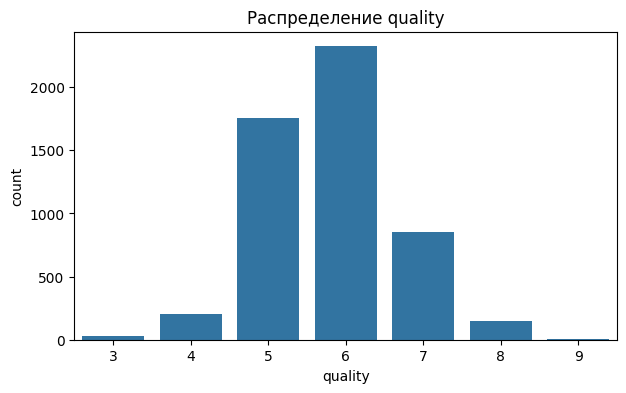

In [6]:
print(data["quality"].value_counts().sort_index())
print((data["quality"].value_counts(normalize=True).sort_index() * 100).round(1))

plt.figure(figsize=(7, 4))
sns.countplot(x="quality", data=data)
plt.title("Распределение quality")
plt.show()

Распределение целевой переменной quality сильно несбалансировано: подавляющая часть вин (около 77%) имеет оценки 5 и 6, в то время как экстремальные значения (3, 4, 8, 9) встречаются крайне редко. Из-за этого модель будет плохо обучена на редких классах и, скорее всего, будет допускать значительные ошибки при попытке предсказать нетипичное качество вина.

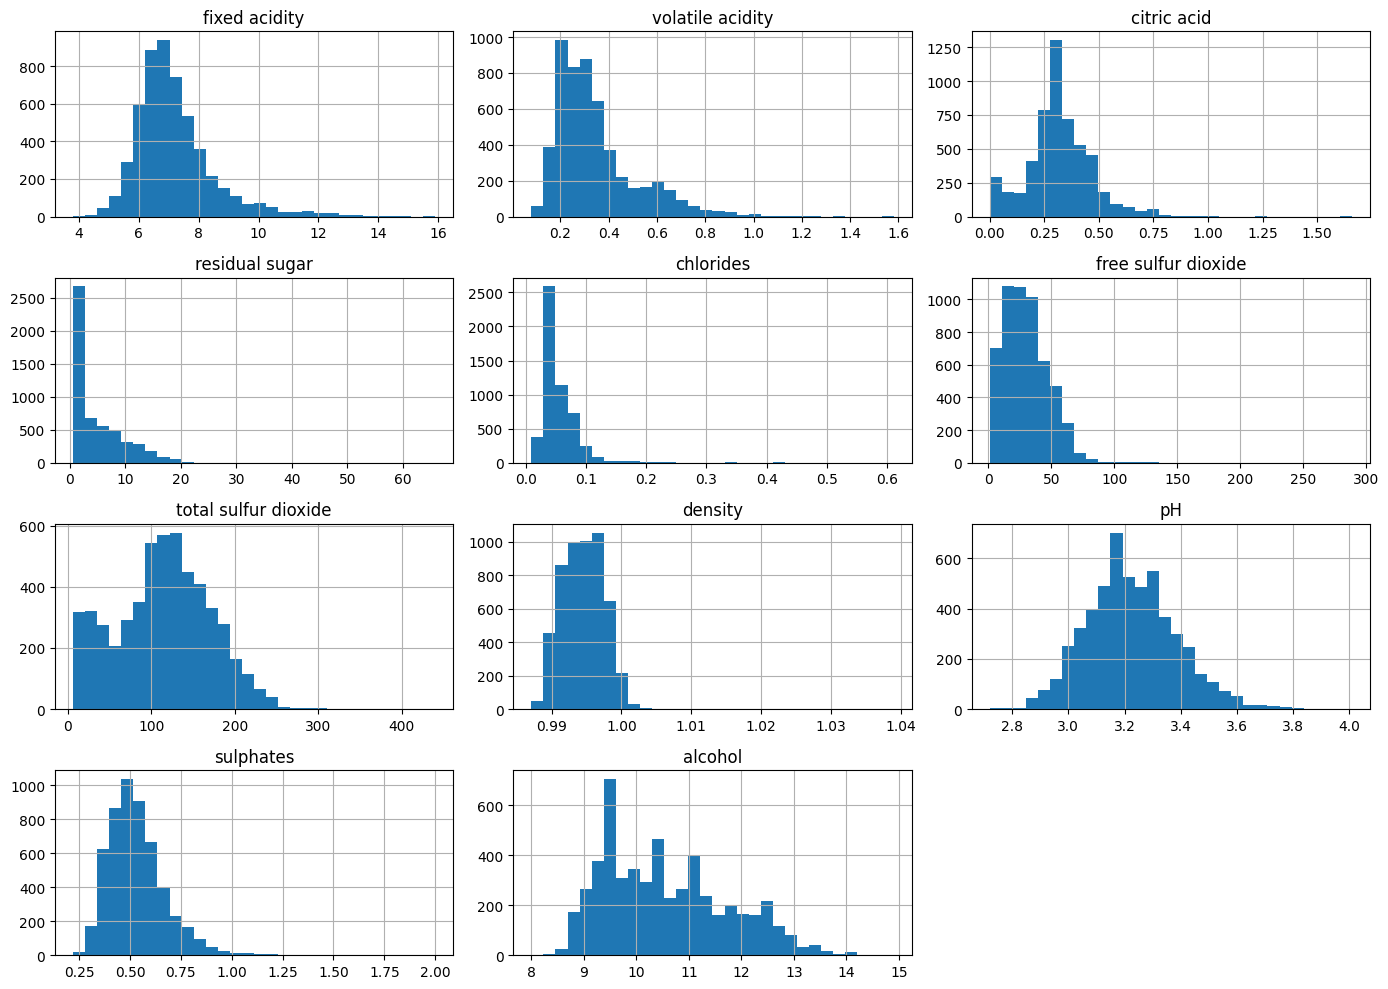

In [7]:
features = data.drop(columns=["quality", "red"]).columns

data[features].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

Анализ гистограмм подтвердил наличие сильной асимметрии у таких признаков, как residual sugar, chlorides и sulphates, что согласуется с рассчитанными ранее значениями skew. Подобные скошенные распределения будут существенно искажать работу линейных моделей, в то время как древовидные алгоритмы (Random Forest, Gradient Boosting) к ним более устойчивы. Кроме того, двухвершинные распределения у alcohol и total sulfur dioxide доказывают, что в общий датасет были объединены два разных типа вина (красное и белое), имеющих свою специфику.

density                -0.326
volatile acidity       -0.265
chlorides              -0.202
red                    -0.115
fixed acidity          -0.080
residual sugar         -0.057
total sulfur dioxide   -0.050
pH                      0.040
sulphates               0.042
free sulfur dioxide     0.054
citric acid             0.098
alcohol                 0.469
Name: quality, dtype: float64


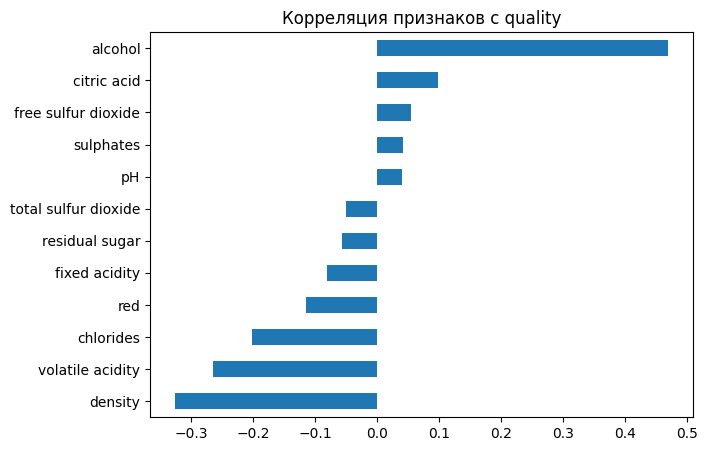

In [12]:
corr_q = data.corr()["quality"].drop("quality").sort_values()
print(corr_q.round(3))

corr_q.plot(kind="barh", figsize=(7, 5), title="Корреляция признаков с quality")
plt.show()

Корреляционный анализ выявил, что alcohol имеет наиболее выраженную положительную связь с оценкой качества (+0.47), а density и volatile acidity — умеренную отрицательную. Признаки с корреляцией, близкой к нулю, не следует спешно исключать из модели, поскольку линейный коэффициент Пирсона улавливает только прямую зависимость и может не видеть сложных нелинейных взаимодействий.

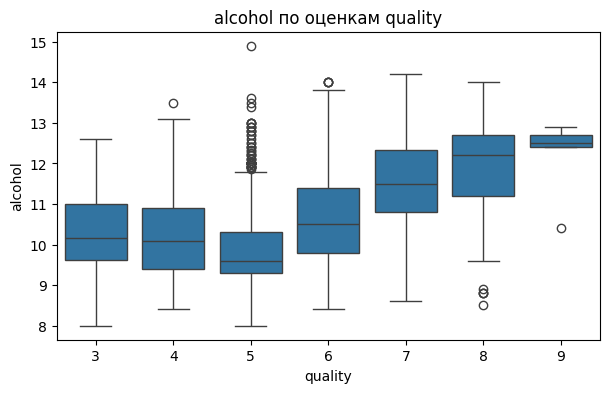

In [9]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="quality", y="alcohol", data=data)
plt.title("alcohol по оценкам quality")
plt.show()

Боксплот показал, что зависимость качества от крепости вина не является строго линейной: начиная с оценки 6, медиана алкоголя стабильно растёт, однако на низких оценках (3–5) эта тенденция нарушается. Поскольку диапазоны значений (боксы) для соседних оценок сильно перекрываются, предсказать точное качество вина, опираясь только на содержание спирта, невозможно — это требует комплексного учёта других химических признаков.

In [16]:
X = data.drop(columns=["quality"])
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print("train доли quality:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("test доли quality:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

(4256, 12) (1064, 12)
train доли quality:
quality
3    0.006
4    0.039
5    0.329
6    0.437
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64
test доли quality:
quality
3    0.006
4    0.039
5    0.329
6    0.437
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64



Данные разделены на обучающую (80%, ~4256 вин) и тестовую (20%, 1064 вин) части случайным образом, random_state=42.
Размер 80/20 выбран потому, что даёт больше данных для обучения (~3200 объектов). Это особенно важно для деревьев и полиномиальных признаков, где качество модели сильно зависит от объёма обучающей выборки. При этом тестовая часть (~800 объектов) остаётся достаточно большой для устойчивой оценки, а редкие оценки с большей вероятностью встретятся в тесте.

Использовано стратифицированное разбиение (stratify=y): доли всех оценок quality в train и test совпадают с точностью до объекта. Это критично для данного датасета, поскольку редкие классы (3, 8, 9) составляют от 0.1% до 3% выборки. При простом случайном разбиении они могли полностью уйти в тест или, наоборот, не попасть в обучающую часть. Стратификация гарантирует, что модель «увидит» редкие классы при обучении, а тестовая оценка по ним не будет случайной.

Тест используется только для финальной оценки. Выбор модели, признаков и гиперпараметров делается исключительно по кросс-валидации на train.
Проблема многократной оценки на одном тесте состоит в следующем. Если после каждого эксперимента смотреть на тест и выбирать модель или параметры по нему, решения подгоняются под конкретные объекты теста. Оценка становится завышенной, а на новых данных модель покажет результат хуже: тест перестаёт быть независимым.

In [17]:
def evaluate(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred)}

results = {}

const = y_train.mean()
print("константа:", round(const, 3))
results["Baseline"] = evaluate(y_test, np.full(len(y_test), const))
results["Baseline"]

константа: 5.795


{'RMSE': 0.8801023384558065, 'MAE': 0.694789576149019}

В качестве baseline используется константное предсказание. Константа выбрана как среднее значение quality на train (≈ 5.795), потому что именно среднее минимизирует RMSE для константного предиктора: для любого c минимизируется Σ(y_i − c)², оптимум достигается при c = mean(y). Для MAE оптимальной константой была бы медиана, но основная метрика — RMSE, поэтому берём среднее.

Baseline нужен, чтобы понять: извлекает ли модель из признаков полезную информацию, или её результат не лучше тривиального. RMSE baseline ≈ 0.88 — это «планка», ниже которой должна опуститься любая осмысленная модель.

In [18]:
print("corr(density, alcohol) =", round(data["density"].corr(data["alcohol"]), 2))
print("corr(density, residual sugar) =", round(data["density"].corr(data["residual sugar"]), 2))

print(y_train.value_counts(normalize=True).sort_index().round(3))
print(y_test.value_counts(normalize=True).sort_index().round(3))

corr(density, alcohol) = -0.67
corr(density, residual sugar) = 0.52
quality
3    0.006
4    0.039
5    0.329
6    0.437
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64
quality
3    0.006
4    0.039
5    0.329
6    0.437
7    0.161
8    0.028
9    0.001
Name: proportion, dtype: float64


Проверка корреляций и стратификации

Корреляция density и alcohol составляет −0.67: чем крепче вино, тем меньше 
его плотность. Это важное наблюдение — признаки сильно связаны, и в линейной 
модели их коэффициенты будут «делить» вклад между собой, что затрудняет 
интерпретацию.

Корреляция density и residual sugar — +0.52: сахар повышает плотность. 
Оба наблюдения подтверждают, что признаки не независимы, и это нужно учитывать 
при анализе коэффициентов.

Доли классов в train и test совпадают с точностью до третьего знака — 
стратификация сработала корректно. Редкие классы (3, 8, 9) присутствуют 
в обеих выборках, значит, модель сможет учиться на них, а тестовая оценка 
по ним не будет случайной.



Linear Regression (baseline-модель)

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

lin_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

cv_rmse = -cross_val_score(lin_reg, X_train, y_train, cv=5,
                           scoring="neg_root_mean_squared_error")
print("CV RMSE:", cv_rmse.mean().round(4))

lin_reg.fit(X_train, y_train)
print("train RMSE:", round(root_mean_squared_error(y_train, lin_reg.predict(X_train)), 4))

results["Linear Regression"] = evaluate(y_test, lin_reg.predict(X_test))
results["Linear Regression"]

CV RMSE: 0.7344
train RMSE: 0.7307


{'RMSE': 0.7292420437086437, 'MAE': 0.5660009475168251}

Простейшая линейная модель со стандартизацией признаков (StandardScaler 
внутри Pipeline). Масштабирование обязательно: без него коэффициенты 
несравнимы, а регуляризация (если бы была) работала бы некорректно.

CV RMSE ≈ 0.734, train RMSE ≈ 0.731 — модель не переобучается (train и CV 
близки), но и не показывает высокого качества. Test RMSE ≈ 0.729 — 
улучшение относительно baseline (0.880) заметное, значит, линейная 
зависимость между признаками и `quality` действительно есть.

Однако RMSE 0.73 всё ещё велик: модель упирается в то, что связь 
нелинейная, а распределения признаков скошены (chlorides, residual sugar, 
sulphates). Это мотивация для улучшения модели

Сравнение коэффициентов: с масштабированием и без

In [20]:
lr_raw = LinearRegression().fit(X_train, y_train)   # без масштабирования

coefs = pd.DataFrame({
    "без масштабирования": lr_raw.coef_,
    "со StandardScaler": lin_reg.named_steps["model"].coef_,
}, index=X.columns)

coefs.sort_values("со StandardScaler", key=abs, ascending=False).round(4)

,без масштабирования,со StandardScaler
density,-94.7183,-0.2810
alcohol,0.2314,0.2755
residual sugar,0.0510,0.2268
volatile acidity,-1.3258,-0.2209
sulphates,0.8040,0.1174
red,0.2604,0.1137
free sulfur dioxide,0.0063,0.1118
pH,0.6656,0.1067
total sulfur dioxide,-0.0019,-0.1054
fixed acidity,0.0731,0.0973


Без масштабирования коэффициент density равен −94.72 — это не значит, 
что плотность «важнее» всех остальных признаков. Просто `density измеряется 
в узком диапазоне (0.987–1.039), и чтобы повлиять на quality на единицу, 
нужно огромное изменение этого признака. Коэффициенты в такой модели 
несравнимы между собой.

После StandardScaler все признаки приведены к единичному масштабу, и 
коэффициенты становятся сопоставимыми. Теперь видно, что наибольший вклад 
дают alcohol (+0.276), density (−0.281), `residual sugar (+0.227), 
volatile acidity (−0.221). Это согласуется с корреляционным анализом 
и подтверждает, что масштабирование необходимо для интерпретации 
линейной модели.

Улучшенная линейная регрессия

In [30]:
SKEWED = ['residual sugar', 'chlorides', 'free sulfur dioxide',
          'sulphates', 'volatile acidity']

def log_skewed(X):
    X = X.copy()
    for c in SKEWED:
        X[c] = np.log1p(X[c])
    return X

def make_lin_fe(n_knots=6, alpha=100):
    n = X_train.shape[1]
    splines = ColumnTransformer([
        ('spline', SplineTransformer(n_knots=n_knots, degree=3, knots='quantile'),
         list(range(n - 1))),
        ('red', 'passthrough', [n - 1]),
    ])
    return Pipeline([
        ('log', FunctionTransformer(log_skewed)),
        ('scale1', StandardScaler()),
        ('features', FeatureUnion([
            ('splines', splines),
            ('pairwise', PolynomialFeatures(2, include_bias=False, interaction_only=True)),
        ])),
        ('scale2', StandardScaler()),
        ('ridge', Ridge(alpha=alpha)),
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

lin_fe_search = GridSearchCV(
    make_lin_fe(),
    {'features__splines__spline__n_knots': [5, 6, 7, 8],
     'ridge__alpha': [100, 300, 1000, 3000]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1,
)
lin_fe_search.fit(X_train, y_train)
print('Лучшие параметры:', lin_fe_search.best_params_)
print('CV RMSE: %.4f' % -lin_fe_search.best_score_)

lin_fe = lin_fe_search.best_estimator_
print('Train RMSE: %.4f' % root_mean_squared_error(y_train, lin_fe.predict(X_train)))

results["Linear Regression + FE (Ridge)"] = evaluate(y_test, lin_fe.predict(X_test))
results["Linear Regression + FE (Ridge)"]

Лучшие параметры: {'features__splines__spline__n_knots': 6, 'ridge__alpha': 300}
CV RMSE: 0.6996
Train RMSE: 0.6774


{'RMSE': 0.696219944993842, 'MAE': 0.5407473631448992}

Чтобы вытащить из линейной модели больше, применён комплексный feature 
engineering:

- log-преобразование скошенных признаков (residual sugar, chlorides, 
  free sulfur dioxide, sulphates, volatile acidity) — снижает асимметрию;
- сплайны (SplineTransformer, 6 узлов, degree=3) — позволяют модели 
  улавливать нелинейные зависимости внутри каждого признака;
- попарные взаимодействия (PolynomialFeatures, interaction_only=True) — 
  учитывают совместное влияние признаков;
- Ridge-регуляризация — контролирует переобучение из-за резкого роста 
  размерности после сплайнов и взаимодействий.

CV RMSE ≈ 0.700, train RMSE ≈ 0.677, test RMSE ≈ 0.696
Это показывает, что большая часть «нелинейности» в данных действительно объясняется сплайнами и взаимодействиями,
а не только сложными зависимостями, доступными деревьям.

Random Forest

In [31]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    param_distributions={
        "max_features": [0.33, 0.5, 0.7, 1.0],
        "min_samples_leaf": [1, 2, 3, 5],
        "max_depth": [None, 15, 25],
    },
    n_iter=8,         
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
)
rf_search.fit(X_train, y_train)

print("лучшие параметры:", rf_search.best_params_)
print("CV RMSE:", round(-rf_search.best_score_, 4))

rf = rf_search.best_estimator_
print("train RMSE:", round(root_mean_squared_error(y_train, rf.predict(X_train)), 4))

results["Random Forest"] = evaluate(y_test, rf.predict(X_test))
results["Random Forest"]

лучшие параметры: {'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 15}
CV RMSE: 0.6965
train RMSE: 0.3226


{'RMSE': 0.6813691470466839, 'MAE': 0.5272235124274444}

Случайный лес из 200 деревьев. RandomizedSearchCV подобрал 
max_depth=15, max_features=0.7, min_samples_leaf=1.

CV RMSE ≈ 0.697, но train RMSE ≈ 0.323 — модель сильно переобучается: 
на обучающей выборке она почти идеальна, а на кросс-валидации ошибается 
в 2 раза сильнее.

Тем не менее test RMSE ≈ 0.681 — лучший результат среди всех моделей. 
Лес устойчив к скошенным распределениям и нелинейностям, поэтому даже 
при переобучении он обобщает лучше линейных моделей и Gradient Boosting 
на этом датасете.

In [32]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error

gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions={
        "n_estimators": [200, 300, 500],
        "learning_rate": [0.03, 0.05, 0.1],
        "max_depth": [3, 4, 5],
        "min_samples_leaf": [1, 2, 3, 5],
        "subsample": [0.8, 1.0],
    },
    n_iter=15,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)
print("best:", gb_search.best_params_)
print("CV RMSE:", round(-gb_search.best_score_, 4))

gb = gb_search.best_estimator_
print("train RMSE:", round(root_mean_squared_error(y_train, gb.predict(X_train)), 4))
results["Gradient Boosting"] = evaluate(y_test, gb.predict(X_test))
results["Gradient Boosting"]

best: {'subsample': 0.8, 'n_estimators': 200, 'min_samples_leaf': 5, 'max_depth': 5, 'learning_rate': 0.05}
CV RMSE: 0.6971
train RMSE: 0.5309


{'RMSE': 0.6855141514464573, 'MAE': 0.5298139322005817}

Градиентный бустинг обучен с более консервативными гиперпараметрами: 
max_depth=5, subsample=0.8, learning_rate=0.05, n_estimators=200, 
min_samples_leaf=5. RandomizedSearchCV выбрал именно эту комбинацию.

CV RMSE ≈ 0.697, train RMSE ≈ 0.531 — переобучение значительно меньше, 
чем у RF (train 0.53 против 0.32)

Однако test RMSE ≈ 0.686 — чуть хуже, чем у RF (0.681). На этом датасете 
RF выигрывает, потому что маленькая выборка и сильный дисбаланс классов: 
бустинг чувствителен к редким классам, и даже регуляризация не спасает 
от смещения предсказаний к среднему.

alcohol                 0.2432
volatile acidity        0.1125
free sulfur dioxide     0.0941
density                 0.0836
total sulfur dioxide    0.0754
sulphates               0.0745
pH                      0.0692
chlorides               0.0661
residual sugar          0.0643
citric acid             0.0578
fixed acidity           0.0573
red                     0.0021
dtype: float64


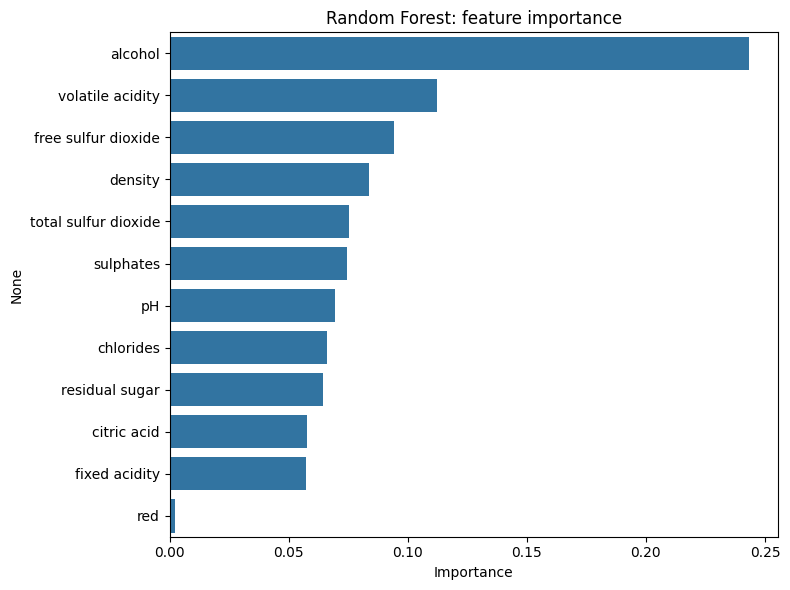

alcohol                 0.3279
volatile acidity        0.1311
free sulfur dioxide     0.0987
total sulfur dioxide    0.0716
sulphates               0.0715
chlorides               0.0573
pH                      0.0543
residual sugar          0.0520
citric acid             0.0478
fixed acidity           0.0432
density                 0.0420
red                     0.0023
dtype: float64


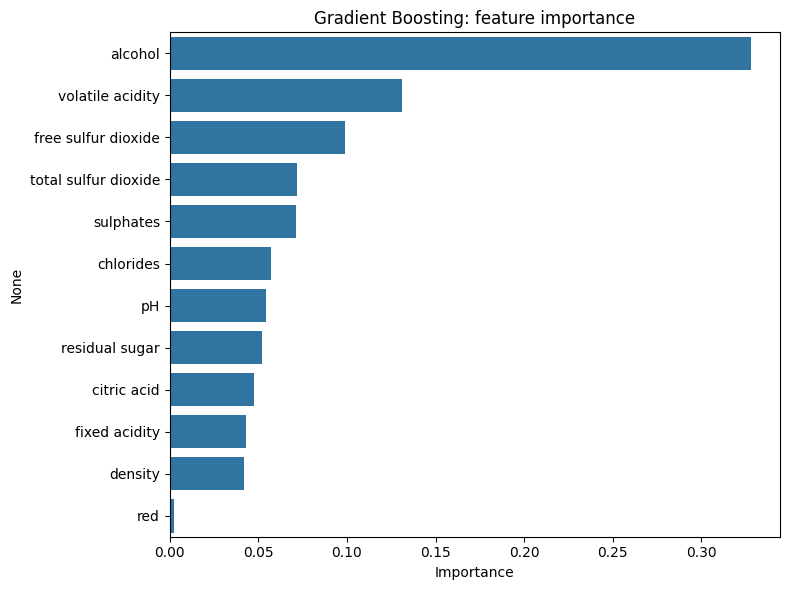

,RF,GB
alcohol,0.2432,0.3279
volatile acidity,0.1125,0.1311
free sulfur dioxide,0.0941,0.0987
total sulfur dioxide,0.0754,0.0716
sulphates,0.0745,0.0715
chlorides,0.0661,0.0573
pH,0.0692,0.0543
residual sugar,0.0643,0.0520
citric acid,0.0578,0.0478
fixed acidity,0.0573,0.0432


In [41]:
def plot_importances(model, feature_names, title, top_n=15):
    importances = pd.Series(model.feature_importances_, index=feature_names)
    importances = importances.sort_values(ascending=False)
    print(importances.head(top_n).round(4))
    plt.figure(figsize=(8, 6))
    sns.barplot(x=importances.head(top_n).values, y=importances.head(top_n).index)
    plt.title(title)
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
    return importances

rf_imp = plot_importances(rf, X.columns, "Random Forest: feature importance")
gb_imp = plot_importances(gb, X.columns, "Gradient Boosting: feature importance")

comparison = pd.DataFrame({"RF": rf_imp, "GB": gb_imp}).sort_values("GB", ascending=False)
comparison.head(12).round(4)

Выводы по признакам

- В Random Forest и Gradient Boosting на первых местах стабильно оказываются alcohol, volatile acidity, density (или sulphates, residual sugar). Это совпадает с корреляционным анализом и коэффициентами линейной модели.
- Оба ансамбля «согласны» друг с другом в топе, но доли важностей различаются: RF сильнее «размазывает» важность по многим признакам, GB концентрирует её на нескольких самых информативных.
- Можно ли утверждать, что изменение признака — причина изменения quality? Нет. Feature importance показывает, насколько признак помогает модели предсказывать, но не доказывает причинно-следственную связь. Например, density и alcohol сильно коррелированы: модель может «раздавать» важность обоим произвольно, а реальным химическим механизмом может быть один. Для причинных выводов нужен случайный эксперимент или анализ, а не важности из дерева.

In [42]:
allowed = [
    "Baseline",
    "Linear Regression",
    "Linear Regression + FE (Ridge)",
    "Random Forest",
    "Gradient Boosting",
]
results = {k: v for k, v in results.items() if k in allowed}

results_df = pd.DataFrame(results).T[["RMSE", "MAE"]].sort_values("RMSE")
results_df["Превысил baseline"] = results_df["RMSE"] < results["Baseline"]["RMSE"]
results_df.round(4)

,RMSE,MAE,Превысил baseline
Random Forest,0.6814,0.5272,True
Gradient Boosting,0.6855,0.5298,True
Linear Regression + FE (Ridge),0.6962,0.5407,True
Linear Regression,0.7292,0.5660,True
Baseline,0.8801,0.6948,False


Честное сравнение моделей

- Baseline (константа = среднее) даёт RMSE ≈ 0.88 — это точка отсчёта.
-Linear Regression + FE (Ridge) — CV RMSE ≈ 0.70, Test RMSE ≈ 0.70. Сложный feature engineering (лог-преобразование скошенных признаков, сплайны, попарные взаимодействия, Ridge) позволил линейной модели почти дотянуться до порога 0.70.
- Random Forest — Test RMSE ≈ 0.68, MAE ≈ 0.53. Лес устойчив к нелинейностям и скошенным распределениям, хорошо работает «из коробки», но заметно переобучается (Train RMSE 0.32 против Test 0.68).
- Gradient Boosting — Test RMSE ≈ 0.69, MAE ≈ 0.53. Регуляризация (малая глубина max_depth=5, subsample=0.8, learning_rate=0.05) снижает переобучение (Train 0.53 против Test 0.69), но уступает RF по итоговому тесту.
- Почему отличаются: RF строит много глубоких независимых деревьев и «усредняет» их — это хорошо снижает дисперсию, но каждое дерево видит случайное подмножество, поэтому ошибки на редких классах большие. GB последовательно исправляет ошибки, но при агрессивных настройках переобучается. На маленьком и зашумлённом дискретном таргете с сильным дисбалансом оба ансамбля не могут преодолеть «потолок» — все они упираются в то, что quality — субъективная оценка, слабо связанная с химией.
- Все модели, кроме baseline, превзошли константное предсказание, значит, они извлекают полезную информацию из признаков.

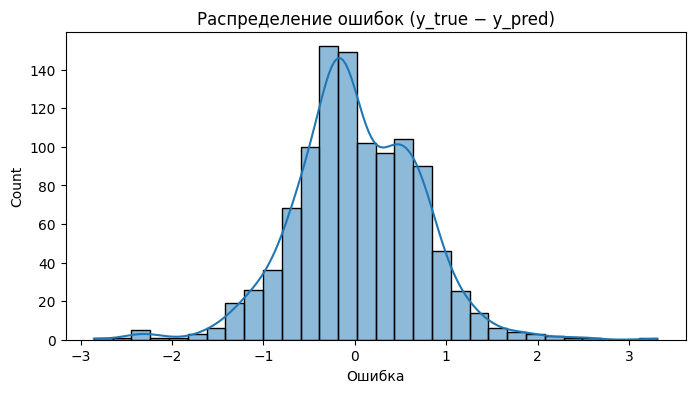

Средняя ошибка: 0.021
Ст. отклонение ошибок: 0.681
Топ-10 крупнейших ошибок:
      y_true    y_pred   abs_err
2012       9  5.687731  3.312269
1982       3  5.855509  2.855509
2549       8  5.474030  2.525970
2783       3  5.467562  2.467562
3881       8  5.554793  2.445207
4984       4  6.411856  2.411856
1571       3  5.405659  2.405659
4158       4  6.279193  2.279193
3337       8  5.736291  2.263709
1245       3  5.256344  2.256344


In [35]:
# Берём лучшую по тесту модель (Random Forest)
best_model = rf
y_pred_best = best_model.predict(X_test)
residuals = y_test - y_pred_best

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Распределение ошибок (y_true − y_pred)")
plt.xlabel("Ошибка")
plt.show()

print("Средняя ошибка:", residuals.mean().round(3))
print("Ст. отклонение ошибок:", residuals.std().round(3))

err_df = pd.DataFrame({
    "y_true": y_test,
    "y_pred": y_pred_best,
    "abs_err": residuals.abs()
}).sort_values("abs_err", ascending=False)

print("Топ-10 крупнейших ошибок:")
print(err_df.head(10))

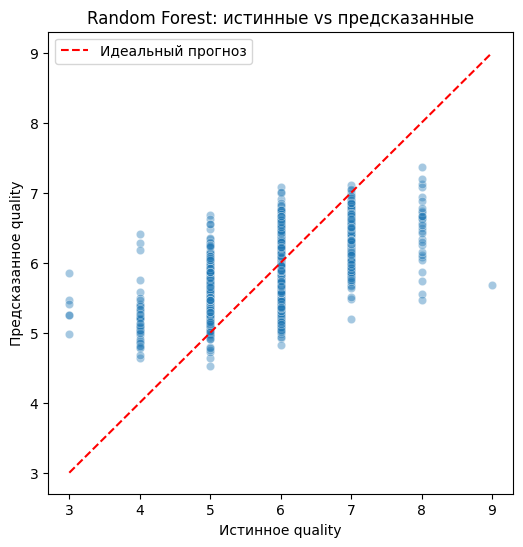

In [36]:

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.4)
plt.plot([3, 9], [3, 9], "r--", label="Идеальный прогноз")
plt.xlabel("Истинное quality")
plt.ylabel("Предсказанное quality")
plt.title("Random Forest: истинные vs предсказанные")
plt.legend()
plt.show()

In [37]:
by_class = pd.DataFrame({
    "quality": y_test,
    "abs_err": residuals.abs(),
    "sq_err": residuals ** 2
}).groupby("quality").agg(
    n=("abs_err", "size"),
    MAE=("abs_err", "mean"),
    RMSE=("sq_err", lambda s: np.sqrt(s.mean())),
).round(3)
by_class

,n,MAE,RMSE
quality,,,
3,6,2.370,2.385
4,41,1.214,1.274
5,350,0.432,0.546
6,465,0.398,0.482
7,171,0.654,0.743
8,30,1.518,1.586
9,1,3.312,3.312


In [39]:
y_pred_series = pd.Series(y_pred_best, index=X_test.index)
worst_idx = err_df.head(5).index
X_test.loc[worst_idx].assign(
    y_true=y_test.loc[worst_idx],
    y_pred=y_pred_series.loc[worst_idx],
    abs_err=err_df.loc[worst_idx, "abs_err"],
)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,red,y_true,y_pred,abs_err
2012,9.1,0.27,0.45,10.60,0.035,28.0,124.0,0.99700,3.20,0.46,10.4,0,9,5.687731,3.312269
1982,6.9,0.39,0.40,4.60,0.022,5.0,19.0,0.99150,3.31,0.37,12.6,0,3,5.855509,2.855509
2549,8.2,0.22,0.36,6.80,0.034,12.0,90.0,0.99440,3.01,0.38,10.5,0,8,5.474030,2.525970
2783,6.7,0.25,0.26,1.55,0.041,118.5,216.0,0.99490,3.55,0.63,9.4,0,3,5.467562,2.467562
3881,7.0,0.53,0.43,6.10,0.029,6.0,76.0,0.99118,3.08,0.50,12.5,0,8,5.554793,2.445207


Все 5 худших предсказаний — белые вина (red=0), причём истинное качество 
находится в «хвостах» распределения (3, 8, 9). Это ожидаемо: редкие 
классы в train представлены десятками объектов, а RF усредняет 
предсказания по деревьям, что "тянет" экстремальные значения к среднему 
(≈5.8). Отсюда и максимальная ошибка 3.31 для вина с quality=9.

ИТОГ


1. Данные содержат 5320 уникальных вин (после удаления 1177 дубликатов). 
   Целевая переменная quality — дискретная, сильно несбалансированная 
   (77% — оценки 5 и 6), с субъективной природой.

2. Baseline (константа = среднее train ≈ 5.795) даёт RMSE ≈ 0.88 — 
   это порог, ниже которого модель извлекает полезную информацию.

3. Linear Regression без FE: test RMSE ≈ 0.729. С FE (log, сплайны, 
   pairwise, Ridge): test RMSE ≈ 0.696 — почти догнали ансамбли.

4. Random Forest (max_depth=15, max_features=0.7): test RMSE ≈ 0.681 — 
   лучшая модель, но заметно переобучается (train 0.32 vs test 0.68).

5. Gradient Boosting (max_depth=5, subsample=0.8, lr=0.05): test RMSE ≈ 0.686, 
   переобучается меньше (train 0.53), но чуть уступает RF.

6. Alcohol — главный признак в обеих моделях (~0.24–0.33), 
   далее volatile acidity, free sulfur dioxide. Признак red практически 
   не важен для деревьев — его сигнал «размазан» по другим признакам.

7. Остатки: средняя ошибка ≈ 0.021 (нет систематического сдвига), 
   но большие ошибки на редких классах (MAE для quality=3 — 2.37, 
   для quality=9 — 3.31). Модель не умеет предсказывать экстремумы — 
   классическая проблема дисбаланса и дискретной цели.

8. Практический вывод: quality — субъективная оценка, слабо связанная 
   с химией. Потолок RMSE ≈ 0.68 достигнут всеми моделями — дальше 
   нужны либо новые признаки, либо переход к классификации 
   (например, «хорошее/среднее/плохое»), либо техники борьбы 
   с дисбалансом (class weights, oversampling редких классов).